In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/ml-2/bmd.csv")
df.head()

Mounted at /content/drive


,id,age,sex,fracture,weight_kg,height_cm,medication,waiting_time,bmd
0,469,57.052768,F,no fracture,64.0,155.5,Anticonvulsant,18,0.8793
1,8724,75.741225,F,no fracture,78.0,162.0,No medication,56,0.7946
2,6736,70.778900,M,no fracture,73.0,170.5,No medication,10,0.9067
3,24180,78.247175,F,no fracture,60.0,148.0,No medication,14,0.7112
4,17072,54.191877,M,no fracture,55.0,161.0,No medication,20,0.7909


In [ ]:
X = df.drop("bmd", axis=1)
y = df["bmd"]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

trainX, testX, trainY, testY = train_test_split(X, y)

model = Pipeline([
    ("preprocess", ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), ["age", "weight_kg", "height_cm", "waiting_time"]),
            ("cat", OneHotEncoder(drop='first'), ["sex", "fracture", "medication"]),
        ]
    )),
    ("regressor", LinearRegression())
])

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

model.fit(trainX, trainY)

prediction = model.predict(testX)

errorMSE = mean_squared_error(testY, prediction)
errorRMSE = np.sqrt(errorMSE)
errorMAE = mean_absolute_error(testY, prediction)

print(f"Mean Squared Error: {errorMSE}")
print(f"Root Mean Squared Error: {errorRMSE}")
print(f"Mean Absolute Error: {errorMAE}")

Mean Squared Error: 0.009835479882418428
Root Mean Squared Error: 0.09917398793241314
Mean Absolute Error: 0.0821452140951378


MSE (Mean Squared Error) = 0.0113
RMSE (Root Mean Squared Error) = 0.10663
MAE (Mean Absolute Error) = 0.08547

عدد مربوط به معیار اول که مقدارش 0.0113 شده نشون ميده ميانگين خطاي مربعي مدل پايين بوده. تو اين روش خطاها قبل از ميانگين گرفتن به توان دو ميرسن و واسه همين اشتباه هاي بزرگ اثر بيشتري روي نتيجه ميذارن. کم بودن اين عدد يعني مدل از نظر خطاهاي بزرگ وضعيت بدي نداشته. البته چون اين عدد تو مقیاس اصلي تراکم استخوان نيست، نميشه خيلي مستقيم فهميد يعني چقدر از مقدار واقعي دور بوده. اين معيار معمولا وقتي بيشتر به درد ميخوره که بخواهيم اشتباه هاي بزرگ اهميت زيادي داشته باشن.

عدد معيار دوم که مقدارش 0.10663 شده نشون ميده پيش بيني هاي مدل به طور متوسط حدود يک دهم واحد تراکم استخوان با مقدار واقعي فاصله داشتن. چون اين معيار ريشه معيار قبليه، دوباره به همون مقیاس اصلي داده برميگرده و فهميدنش راحت تر ميشه. وقتي بخواهيم مقدار خطا رو در همون مقیاس مقدار واقعي ببينيم و راحت بشه مقايسه کرد، اين معيار مناسب تره و همزمان حساسيت نسبت به خطاهاي بزرگ رو هم حفظ ميکنه.

عدد معيار سوم که مقدارش 0.08547 شده ميگه مدل به طور متوسط حدود صفر ممیز هشتاد و پنج صدم واحد تراکم استخوان خطا داشته. تو اين روش خطاها به توان دو نميرسن و براي همين چندتا خطاي بزرگ نميتونه نتيجه کلي رو خيلي تغيير بده. اين معيار تصوير ساده تر و ثابت تري از خطاي مدل ميده و وقتي خوبه که بخواهيم همه خطاها به صورت يکنواخت حساب بشن و مقدارهاي غيرعادي بيش از حد رو نتيجه تأثير نذارن.

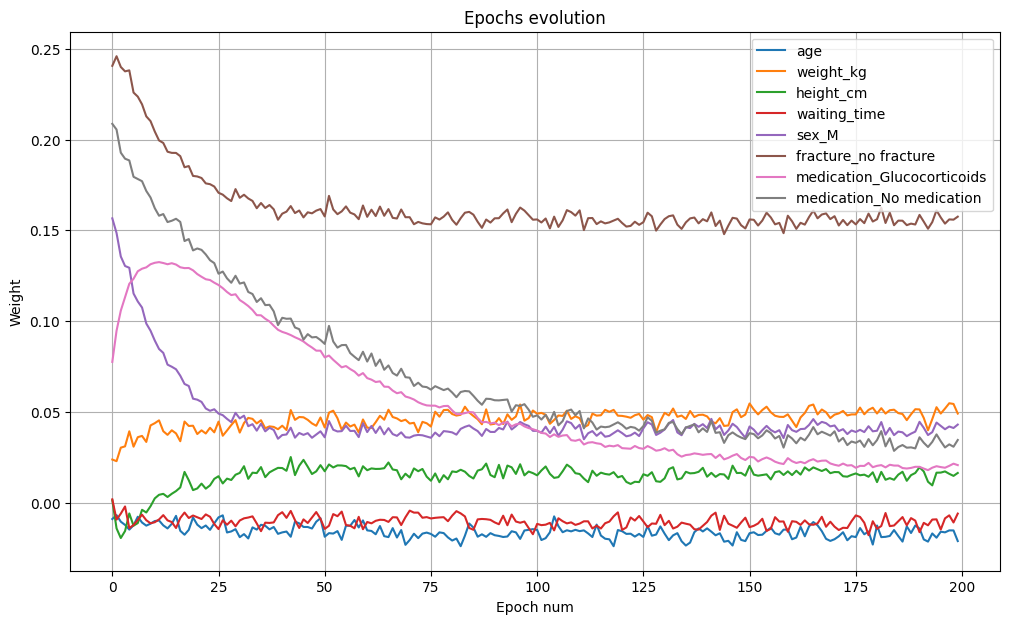

weights akhar: [-0.02118786  0.04906014  0.01633163 -0.00605325  0.04297669  0.15753484
  0.02065172  0.03449907]


In [ ]:
from sklearn.linear_model import SGDRegressor
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["age", "weight_kg", "height_cm", "waiting_time"]),
        ("cat", OneHotEncoder(drop='first'), ["sex", "fracture", "medication"]),
    ]
)

featureNames = list(["age", "weight_kg", "height_cm", "waiting_time"]) \
+ list(preprocessor.fit(trainX).named_transformers_['cat'].get_feature_names_out(
    ["sex", "fracture", "medication"]))

processedTrainX = preprocessor.fit(trainX).transform(trainX)

model = SGDRegressor(
    loss="squared_error",
    eta0=0.01,
    learning_rate="constant",
    max_iter=1,
    warm_start=True
)

weightsOverEpochs = []

for epoch in range(200):
    model.fit(processedTrainX, trainY)
    weightsOverEpochs.append(model.coef_.copy())

weightsOverEpochs = np.array(weightsOverEpochs)

plt.figure(figsize=(12, 7))

for index, feature in enumerate(featureNames):
    plt.plot(weightsOverEpochs[:, index], label=feature)

plt.title("Epochs evolution")
plt.xlabel("Epoch num")
plt.ylabel("Weight")
plt.legend()
plt.grid(True)
plt.show()

print("weights akhar:", weightsOverEpochs[-1])



در روش‌ های گرادیان، با تکرار آپدیت وزن‌ها، گرادیان به سمت صفر
میره و وزن‌ ها به مقداری میرسن که تغییرشون خیلی ناچیز میشه.
که به معنی رسیدن به حداقل خطا در تابع هزینه است.